In [1]:
!pip install numpy matplotlib scikit-learn tensorflow qiskit qiskit-machine-learning qiskit-algorithms

In [2]:
# Section 1: Imports and configuration

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit_algorithms.optimizers import COBYLA

SEED = 42
TOTAL_IMAGES = 10_000
TEST_SIZE = 0.20

# Use identical examples for both classifiers.
MODEL_TRAIN_SIZE = 500

N_QUBITS = 4
VQC_MAXITER = 30
SHOTS = 1024

np.random.seed(SEED)

print("Configuration loaded.")

Configuration loaded.


In [3]:
# Section 2: Load and select exactly 10,000 images

(x_full, y_full), (_, _) = mnist.load_data()

# Select exactly 10,000 images, stratified across digits 0-9.
X_all, _, y_all, _ = train_test_split(
    x_full,
    y_full,
    train_size=TOTAL_IMAGES,
    stratify=y_full,
    random_state=SEED
)

assert len(X_all) == TOTAL_IMAGES
assert len(y_all) == TOTAL_IMAGES
assert set(np.unique(y_all)) == set(range(10))

print("Total images:", len(X_all))
print("Image shape:", X_all.shape[1:])
print("Number of classes:", len(np.unique(y_all)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Total images: 10000
Image shape: (28, 28)
Number of classes: 10


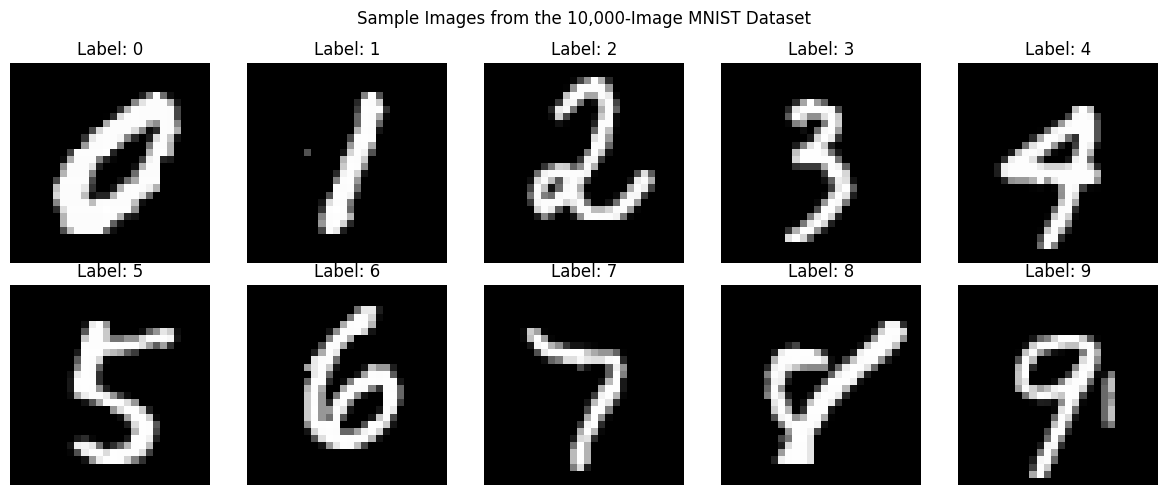

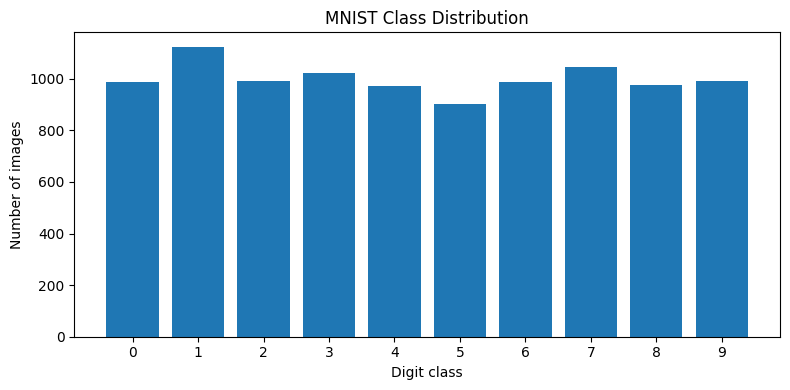

Images per class: [ 987 1124  993 1022  974  904  986 1044  975  991]


In [4]:
# Section 3: Visualize sample images

digit_names = [str(i) for i in range(10)]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for digit, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y_all == digit)[0]
    ax.imshow(X_all[idx], cmap="gray")
    ax.set_title(f"Label: {y_all[idx]}")
    ax.axis("off")

plt.suptitle("Sample Images from the 10,000-Image MNIST Dataset")
plt.tight_layout()
plt.show()

# Class distribution
counts = np.bincount(y_all, minlength=10)

plt.figure(figsize=(8, 4))
plt.bar(digit_names, counts)
plt.xlabel("Digit class")
plt.ylabel("Number of images")
plt.title("MNIST Class Distribution")
plt.xticks(range(10))
plt.tight_layout()
plt.show()

print("Images per class:", counts)

In [5]:
# Section 4: Stratified train-test split

X_train_img, X_test_img, y_train, y_test = train_test_split(
    X_all,
    y_all,
    test_size=TEST_SIZE,
    stratify=y_all,
    random_state=SEED
)

assert len(X_train_img) == 8000
assert len(X_test_img) == 2000

print("Training images:", len(X_train_img))
print("Testing images:", len(X_test_img))

print("\nTraining distribution:", np.bincount(y_train, minlength=10))
print("Testing distribution: ", np.bincount(y_test, minlength=10))

Training images: 8000
Testing images: 2000

Training distribution: [790 899 794 818 779 723 789 835 780 793]
Testing distribution:  [197 225 199 204 195 181 197 209 195 198]


In [6]:
# Section 5: Choose a stratified training subset for practical runtime

X_train_flat = X_train_img.reshape(len(X_train_img), -1).astype(np.float32) / 255.0
X_test_flat = X_test_img.reshape(len(X_test_img), -1).astype(np.float32) / 255.0

# Use the same subset for classical and quantum training.
X_model_img, _, y_model, _ = train_test_split(
    X_train_flat,
    y_train,
    train_size=MODEL_TRAIN_SIZE,
    stratify=y_train,
    random_state=SEED
)

print("Available training split:", len(X_train_flat))
print("Images used to fit each model:", len(X_model_img))
print("Held-out test images:", len(X_test_flat))

# Fit PCA only on the selected training subset.
pca = PCA(n_components=N_QUBITS, random_state=SEED)
X_model_pca = pca.fit_transform(X_model_img)
X_test_pca = pca.transform(X_test_flat)

# Classical model features: standard scaling helps the SVM.
classical_scaler = MinMaxScaler(feature_range=(-1, 1))
X_model_classical = classical_scaler.fit_transform(X_model_pca)
X_test_classical = classical_scaler.transform(X_test_pca)

# Quantum input angles are mapped into [-pi, pi].
quantum_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi))
X_model_quantum = quantum_scaler.fit_transform(X_model_pca)
X_test_quantum = quantum_scaler.transform(X_test_pca)

print("PCA output shape:", X_model_pca.shape)
print("Explained variance by 4 components:",
      round(float(np.sum(pca.explained_variance_ratio_)), 4))

Available training split: 8000
Images used to fit each model: 500
Held-out test images: 2000
PCA output shape: (500, 4)
Explained variance by 4 components: 0.2972


In [7]:
# Section 6: Train the classical model

classical_model = SVC(
    kernel="rbf",
    C=5.0,
    gamma="scale",
    decision_function_shape="ovr"
)

start_time = time.perf_counter()
classical_model.fit(X_model_classical, y_model)
classical_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
y_pred_classical = classical_model.predict(X_test_classical)
classical_inference_time = time.perf_counter() - start_time

print("Classical SVM training time:",
      round(classical_train_time, 3), "seconds")
print("Classical SVM inference time for 2,000 images:",
      round(classical_inference_time, 3), "seconds")

Classical SVM training time: 0.067 seconds
Classical SVM inference time for 2,000 images: 0.06 seconds


In [8]:
# Section 7: Construct the Qiskit VQC

feature_map = ZZFeatureMap(
    feature_dimension=N_QUBITS,
    reps=1
)

ansatz = RealAmplitudes(
    num_qubits=N_QUBITS,
    reps=1
)

sampler = StatevectorSampler(
    default_shots=SHOTS,
    seed=SEED
)

optimizer = COBYLA(maxiter=VQC_MAXITER)

# Map each measured bitstring integer to one of 10 digit classes.
def interpret_bitstring(bitstring):
    return int(bitstring) % 10

quantum_model = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=optimizer,
    sampler=sampler,
    interpret=interpret_bitstring,
    output_shape=10
)

print("Quantum feature map:")
print(feature_map.draw(output="text"))

print("\nVariational ansatz:")
print(ansatz.draw(output="text"))

Quantum feature map:
     ┌────────────────────────────────────┐
q_0: ┤0                                   ├
     │                                    │
q_1: ┤1                                   ├
     │  ZZFeatureMap(x[0],x[1],x[2],x[3]) │
q_2: ┤2                                   ├
     │                                    │
q_3: ┤3                                   ├
     └────────────────────────────────────┘

Variational ansatz:
     ┌──────────────────────────────────────────────────────────┐
q_0: ┤0                                                         ├
     │                                                          │
q_1: ┤1                                                         ├
     │  RealAmplitudes(θ[0],θ[1],θ[2],θ[3],θ[4],θ[5],θ[6],θ[7]) │
q_2: ┤2                                                         ├
     │                                                          │
q_3: ┤3                                                         ├
     └────────────────────────────

C:\Users\csudh\AppData\Local\Temp\ipykernel_14572\2814393209.py:3: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(
C:\Users\csudh\AppData\Local\Temp\ipykernel_14572\2814393209.py:8: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


In [9]:
# Section 8: Train the quantum model and measure training time

start_time = time.perf_counter()
quantum_model.fit(X_model_quantum, y_model)
quantum_train_time = time.perf_counter() - start_time

print("Quantum VQC training time:",
      round(quantum_train_time, 3), "seconds")

Quantum VQC training time: 75.961 seconds


In [10]:
# Section 9: Predict with both models

start_time = time.perf_counter()
y_pred_classical = np.asarray(
    classical_model.predict(X_test_classical)
).astype(int)
classical_inference_time = time.perf_counter() - start_time

start_time = time.perf_counter()
y_pred_quantum = np.asarray(
    quantum_model.predict(X_test_quantum)
).reshape(-1).astype(int)
quantum_inference_time = time.perf_counter() - start_time

assert len(y_pred_classical) == len(y_test) == 2000
assert len(y_pred_quantum) == len(y_test) == 2000

print("Classical inference time:",
      round(classical_inference_time, 3), "seconds")
print("Classical average per image:",
      round(classical_inference_time / len(y_test) * 1000, 3), "ms")

print("\nQuantum inference time:",
      round(quantum_inference_time, 3), "seconds")
print("Quantum average per image:",
      round(quantum_inference_time / len(y_test) * 1000, 3), "ms")

print("\nFirst 20 predictions:")
print("Actual:   ", y_test[:20])
print("Classical:", y_pred_classical[:20])
print("Quantum:  ", y_pred_quantum[:20])

Classical inference time: 0.089 seconds
Classical average per image: 0.045 ms

Quantum inference time: 10.599 seconds
Quantum average per image: 5.3 ms

First 20 predictions:
Actual:    [8 2 1 2 9 0 9 3 7 6 0 8 6 7 9 4 4 4 0 6]
Classical: [0 2 1 2 4 0 4 5 7 6 0 8 4 8 7 4 4 0 0 6]
Quantum:   [1 0 2 4 3 5 2 1 4 3 0 5 4 2 5 1 3 2 1 2]


In [11]:
# Section 10: Evaluation metrics

def calculate_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

classical_metrics = calculate_metrics(
    y_test, y_pred_classical, "Classical SVM"
)

quantum_metrics = calculate_metrics(
    y_test, y_pred_quantum, "Quantum VQC"
)

metrics_df = pd.DataFrame([
    classical_metrics,
    quantum_metrics
])

print(metrics_df.round(4).to_string(index=False))

print("\nCLASSICAL CLASSIFICATION REPORT")
print(classification_report(
    y_test, y_pred_classical,
    labels=list(range(10)),
    target_names=digit_names,
    zero_division=0
))

print("\nQUANTUM CLASSIFICATION REPORT")
print(classification_report(
    y_test, y_pred_quantum,
    labels=list(range(10)),
    target_names=digit_names,
    zero_division=0
))

        Model  Accuracy  Macro Precision  Macro Recall  Macro F1
Classical SVM    0.6175           0.6189        0.6099    0.5979
  Quantum VQC    0.1005           0.0593        0.0993    0.0714

CLASSICAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.68      0.80      0.74       197
           1       0.88      0.91      0.89       225
           2       0.79      0.51      0.62       199
           3       0.73      0.57      0.64       204
           4       0.62      0.65      0.64       195
           5       0.41      0.25      0.31       181
           6       0.62      0.78      0.69       197
           7       0.54      0.77      0.64       209
           8       0.41      0.62      0.49       195
           9       0.51      0.24      0.32       198

    accuracy                           0.62      2000
   macro avg       0.62      0.61      0.60      2000
weighted avg       0.62      0.62      0.60      2000


QUANTUM CLAS

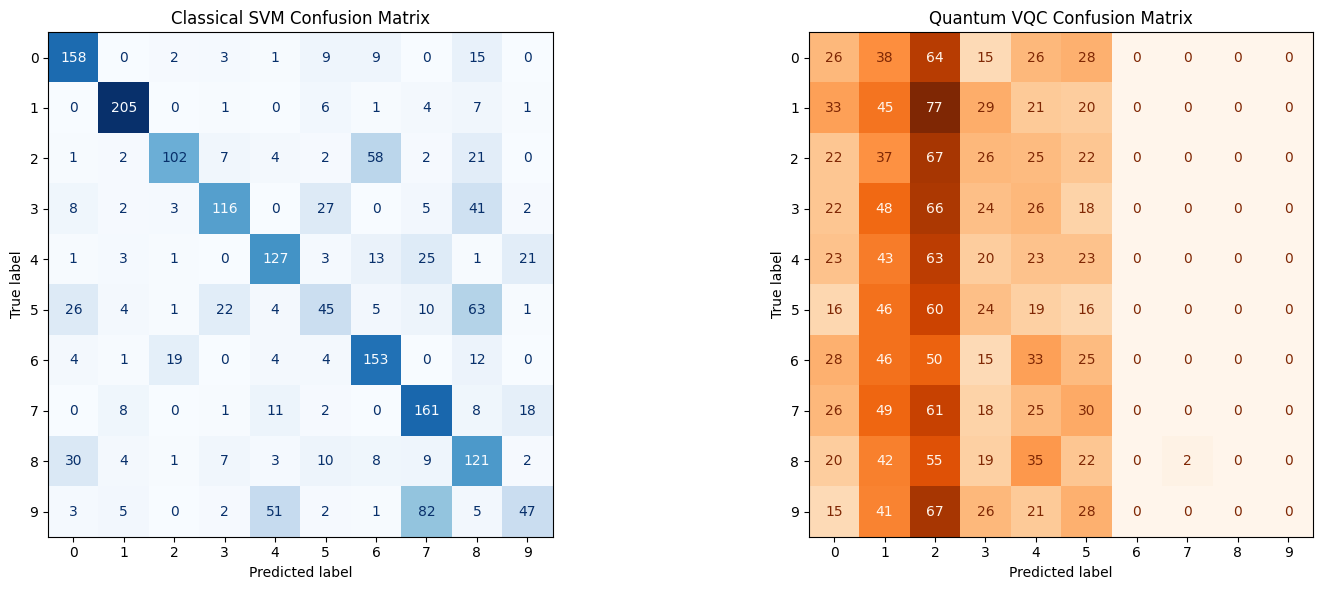

In [12]:
# Section 11: Confusion matrices

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_classical = confusion_matrix(
    y_test, y_pred_classical, labels=range(10)
)
cm_quantum = confusion_matrix(
    y_test, y_pred_quantum, labels=range(10)
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_classical,
    display_labels=range(10)
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Classical SVM Confusion Matrix")

ConfusionMatrixDisplay(
    confusion_matrix=cm_quantum,
    display_labels=range(10)
).plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Quantum VQC Confusion Matrix")

plt.tight_layout()
plt.show()

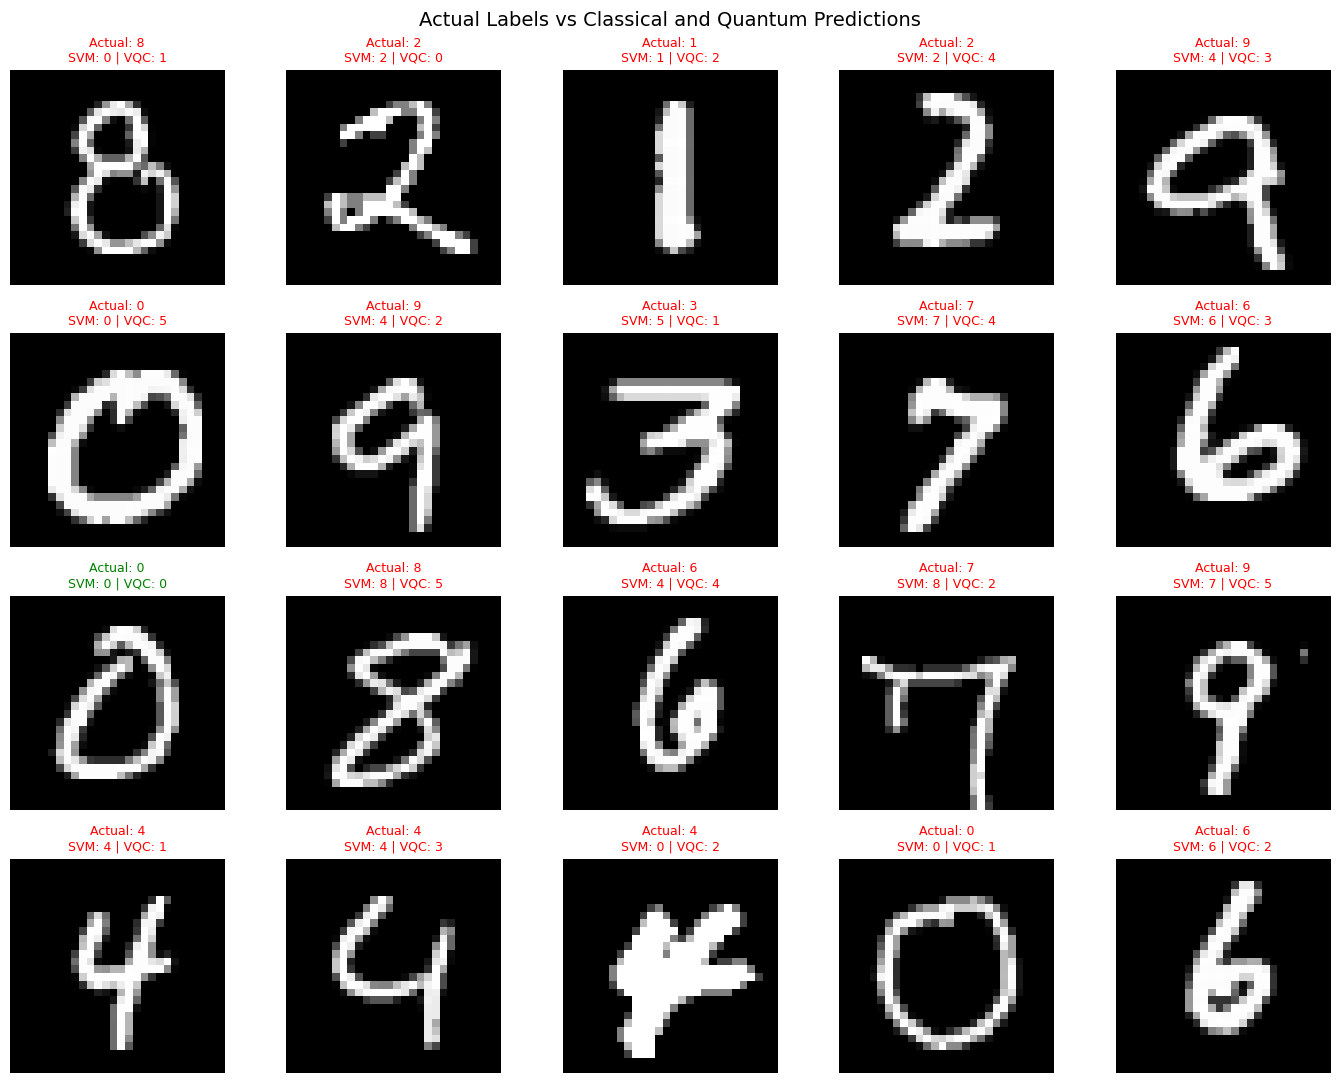

In [ ]:
# Section 12: Compare predictions on individual test images
def show_prediction_grid(
    X_images, y_true, y_classical, y_quantum, n_images=20
):
    n_images = min(n_images, len(y_true))
    fig, axes = plt.subplots(4, 5, figsize=(14, 11))

    for i, ax in enumerate(axes.flat[:n_images]):
        ax.imshow(X_images[i], cmap="gray")

        classical_ok = y_classical[i] == y_true[i]
        quantum_ok = y_quantum[i] == y_true[i]

        ax.set_title(
            f"Actual: {y_true[i]}\n"
            f"SVM: {y_classical[i]} | VQC: {y_quantum[i]}",
            color="green" if classical_ok and quantum_ok else "red",
            fontsize=9
        )
        ax.axis("off")

    plt.suptitle(
        "Actual Labels vs Classical and Quantum Predictions",
        fontsize=14
    )
    plt.tight_layout()
    plt.show()


show_prediction_grid(
    X_test_img, y_test,
    y_pred_classical, y_pred_quantum,
    n_images=20
)

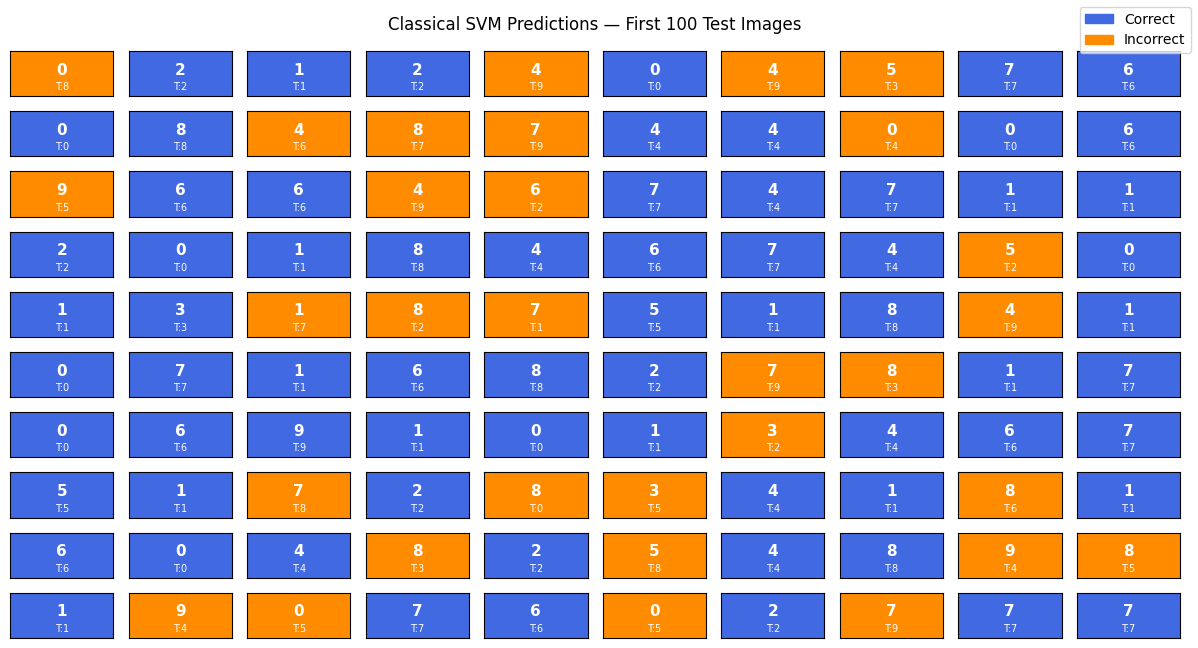

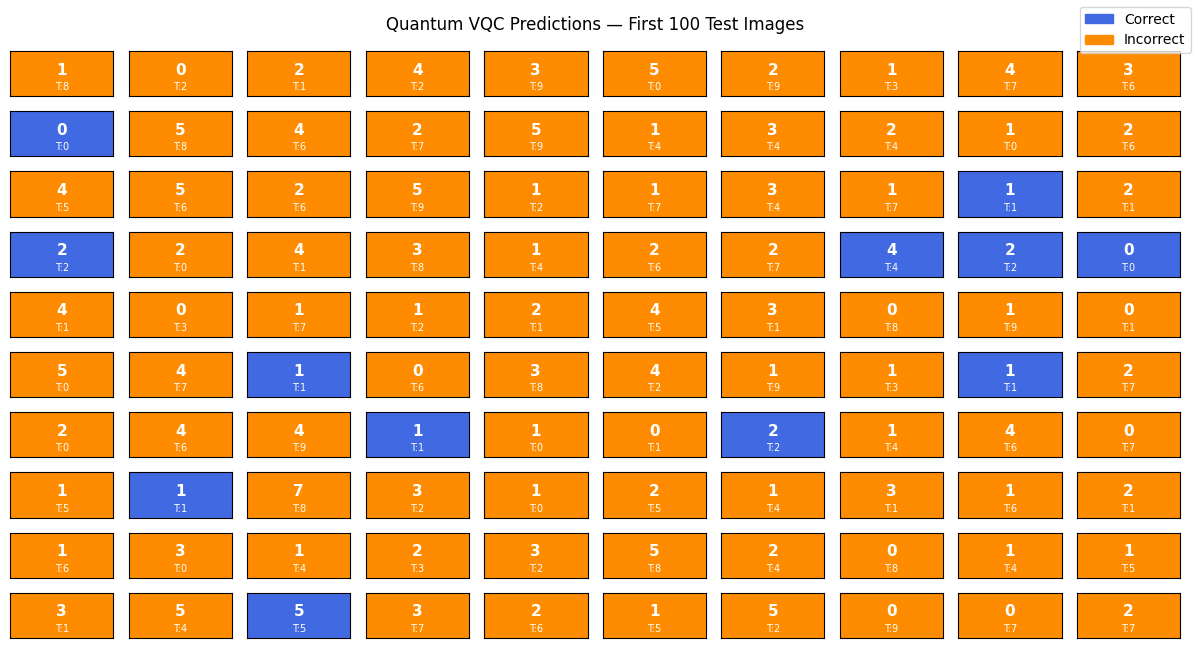

In [ ]:
# Section 13: Colored prediction grids

def show_colored_predictions(y_true, y_pred, title, n=100, ncols=10):
    n = min(n, len(y_true))
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(12, max(4, nrows * 0.65))
    )
    axes = np.asarray(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

        if i < n:
            correct = y_true[i] == y_pred[i]
            square_color = "royalblue" if correct else "darkorange"
            ax.set_facecolor(square_color)
            ax.text(
                0.5, 0.58, str(y_pred[i]),
                ha="center", va="center",
                color="white", fontsize=11, fontweight="bold"
            )
            ax.text(
                0.5, 0.20, f"T:{y_true[i]}",
                ha="center", va="center",
                color="white", fontsize=7
            )
        else:
            ax.axis("off")

    from matplotlib.patches import Patch
    legend_handles = [
        Patch(color="royalblue", label="Correct"),
        Patch(color="darkorange", label="Incorrect")
    ]
    fig.legend(handles=legend_handles, loc="upper right")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_colored_predictions(
    y_test, y_pred_classical,
    "Classical SVM Predictions — First 100 Test Images"
)

show_colored_predictions(
    y_test, y_pred_quantum,
    "Quantum VQC Predictions — First 100 Test Images"
)

        Model  Training Time (s)  Test Inference Time (s)  Average Inference (ms/image)
Classical SVM             0.0671                   0.0892                        0.0446
  Quantum VQC            75.9605                  10.5992                        5.2996


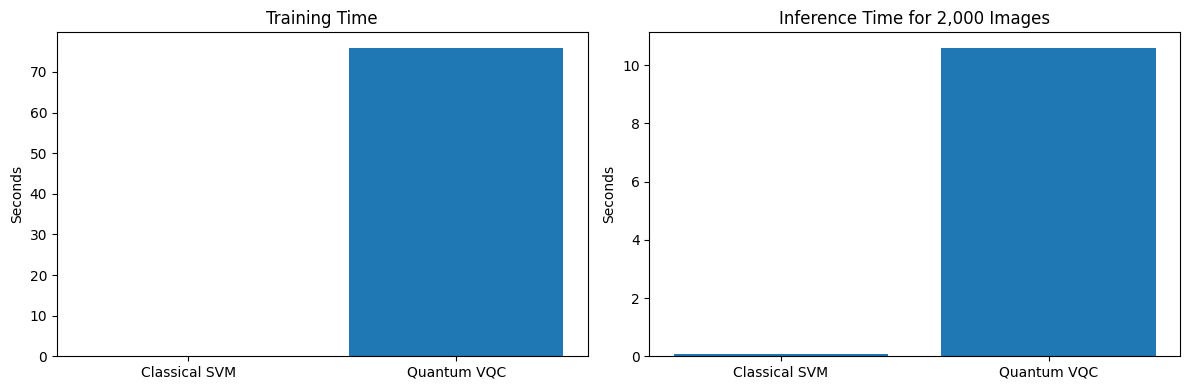

In [ ]:
# Section 14: Runtime comparison
timing_df = pd.DataFrame([
    {
        "Model": "Classical SVM",
        "Training Time (s)": classical_train_time,
        "Test Inference Time (s)": classical_inference_time,
        "Average Inference (ms/image)":
            classical_inference_time / len(y_test) * 1000
    },
    {
        "Model": "Quantum VQC",
        "Training Time (s)": quantum_train_time,
        "Test Inference Time (s)": quantum_inference_time,
        "Average Inference (ms/image)":
            quantum_inference_time / len(y_test) * 1000
    }
])

print(timing_df.round(4).to_string(index=False))

# Runtime visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(
    timing_df["Model"],
    timing_df["Training Time (s)"]
)
axes[0].set_title("Training Time")
axes[0].set_ylabel("Seconds")

axes[1].bar(
    timing_df["Model"],
    timing_df["Test Inference Time (s)"]
)
axes[1].set_title("Inference Time for 2,000 Images")
axes[1].set_ylabel("Seconds")

plt.tight_layout()
plt.show()

In [16]:
# Section 15: Final comparison

final_comparison = metrics_df.merge(
    timing_df,
    on="Model"
)

print("\nFINAL CLASSICAL VS QUANTUM COMPARISON")
print(final_comparison.round(4).to_string(index=False))

# Save the comparison table
final_comparison.to_csv(
    "mnist_classical_vs_quantum_comparison.csv",
    index=False
)

print("\nSaved: mnist_classical_vs_quantum_comparison.csv")


FINAL CLASSICAL VS QUANTUM COMPARISON
        Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Training Time (s)  Test Inference Time (s)  Average Inference (ms/image)
Classical SVM    0.6175           0.6189        0.6099    0.5979             0.0671                   0.0892                        0.0446
  Quantum VQC    0.1005           0.0593        0.0993    0.0714            75.9605                  10.5992                        5.2996

Saved: mnist_classical_vs_quantum_comparison.csv


In [17]:
# Section 16: Export test predictions

predictions_df = pd.DataFrame({
    "Test_Image_Index": np.arange(len(y_test)),
    "Actual_Label": y_test,
    "Classical_Prediction": y_pred_classical,
    "Quantum_Prediction": y_pred_quantum
})

predictions_df["Classical_Correct"] = (
    predictions_df["Actual_Label"]
    == predictions_df["Classical_Prediction"]
)

predictions_df["Quantum_Correct"] = (
    predictions_df["Actual_Label"]
    == predictions_df["Quantum_Prediction"]
)

predictions_df.to_csv(
    "mnist_test_predictions.csv",
    index=False
)

print(predictions_df.head(20).to_string(index=False))
print("\nSaved: mnist_test_predictions.csv")

 Test_Image_Index  Actual_Label  Classical_Prediction  Quantum_Prediction  Classical_Correct  Quantum_Correct
                0             8                     0                   1              False            False
                1             2                     2                   0               True            False
                2             1                     1                   2               True            False
                3             2                     2                   4               True            False
                4             9                     4                   3              False            False
                5             0                     0                   5               True            False
                6             9                     4                   2              False            False
                7             3                     5                   1              False            False
          